## Cellule 1 : Imports et chargement des données nettoyées

In [80]:
import sqlite3
import pandas as pd
from pathlib import Path

pd.set_option("display.max_columns", None)

# Load the cleaned dataset produced in notebook 01
df = pd.read_csv(".../data/marketing_campaign_clean.csv")

# Detect the enrolment date column (DtCustomer or Dt_Customer) and standardize its name
date_col = next(c for c in df.columns if c.lower().replace("_", "") == "dtcustomer")
df = df.rename(columns={date_col: "DtCustomer"})

# Dates are strings again after the CSV round trip: parse them, then store them
# as ISO text (YYYY-MM-DD) so SQLite date functions like strftime() work
df["DtCustomer"] = pd.to_datetime(df["DtCustomer"], errors="coerce")
df["DtCustomer"] = df["DtCustomer"].dt.strftime("%Y-%m-%d")

print(df.shape)
df.head()

(2240, 30)


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,DtCustomer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response,Income_outlier
0,5524,1957,Graduate,Single,58138.0,0.0,0.0,2012-09-04,58.0,635.0,88.0,546.0,172.0,88.0,88.0,3.0,8.0,10.0,4.0,7.0,0,0,0,0,0,0,3,11,1,0
1,2174,1954,Graduate,Single,46344.0,1.0,1.0,2014-03-08,38.0,11.0,1.0,6.0,2.0,1.0,6.0,2.0,1.0,1.0,2.0,5.0,0,0,0,0,0,0,3,11,0,0
2,4141,1965,Graduate,Together,71613.0,0.0,0.0,2013-08-21,26.0,426.0,49.0,127.0,111.0,21.0,42.0,1.0,8.0,2.0,10.0,4.0,0,0,0,0,0,0,3,11,0,0
3,6182,1984,Graduate,Together,26646.0,1.0,0.0,2014-02-10,26.0,11.0,4.0,20.0,10.0,3.0,5.0,2.0,2.0,0.0,4.0,6.0,0,0,0,0,0,0,3,11,0,0
4,5324,1981,PhD,Married,58293.0,1.0,0.0,2014-01-19,94.0,173.0,43.0,118.0,46.0,27.0,15.0,5.0,5.0,3.0,6.0,5.0,0,0,0,0,0,0,3,11,0,0


## Cellule 2 : Connexion SQLite et création de la table

In [82]:
# Connect to a local SQLite database ()
conn = sqlite3.connect("analysis.db")

# Push the dataframe into a SQL table called 'sales'
df.to_sql("sales", conn, if_exists="replace", index=False)

# Sanity check: row count and table structure
print(pd.read_sql("SELECT COUNT(*) AS nb_rows FROM sales", conn))
print(pd.read_sql("PRAGMA table_info(sales)", conn)[["name", "type"]])

   nb_rows
0     2240
                   name     type
0                    ID  INTEGER
1            Year_Birth  INTEGER
2             Education     TEXT
3        Marital_Status     TEXT
4                Income     REAL
5               Kidhome     REAL
6              Teenhome     REAL
7            DtCustomer     TEXT
8               Recency     REAL
9              MntWines     REAL
10            MntFruits     REAL
11      MntMeatProducts     REAL
12      MntFishProducts     REAL
13     MntSweetProducts     REAL
14         MntGoldProds     REAL
15    NumDealsPurchases     REAL
16      NumWebPurchases     REAL
17  NumCatalogPurchases     REAL
18    NumStorePurchases     REAL
19    NumWebVisitsMonth     REAL
20         AcceptedCmp3  INTEGER
21         AcceptedCmp4  INTEGER
22         AcceptedCmp5  INTEGER
23         AcceptedCmp1  INTEGER
24         AcceptedCmp2  INTEGER
25             Complain  INTEGER
26        Z_CostContact  INTEGER
27            Z_Revenue  INTEGER
28             Respon

## Cellule 3 : Requête 1, taux d’acceptation par niveau d’éducation

In [84]:
# Q1: Response rate and average spending by education level
query_1 = """
SELECT
    Education,
    COUNT(*)                                        AS nb_customers,
    SUM(Response)                                   AS nb_accepted,
    ROUND(100.0 * SUM(Response) / COUNT(*), 2)      AS response_rate_pct,
    ROUND(AVG(MntWines + MntFruits + MntMeatProducts + MntFishProducts
              + MntSweetProducts + MntGoldProds), 2) AS avg_total_spent
FROM sales
GROUP BY Education
ORDER BY response_rate_pct DESC;
"""
q1 = pd.read_sql(query_1, conn)
q1

,Education,nb_customers,nb_accepted,response_rate_pct,avg_total_spent
0,PhD,486,101,20.78,672.41
1,Master,573,79,13.79,570.95
2,Graduate,1127,152,13.49,619.90
3,Basic,54,2,3.70,81.80


## Cellule 4 : Requête 2, segmentation par quartile de revenu

In [86]:
# Q2: Customer segments by income quartile (1 = lowest income, 4 = highest)
query_2 = """
WITH spend AS (
    SELECT
        Income,
        Response,
        NumWebPurchases + NumCatalogPurchases + NumStorePurchases AS nb_purchases,
        MntWines + MntFruits + MntMeatProducts + MntFishProducts
            + MntSweetProducts + MntGoldProds                     AS total_spent,
        NTILE(4) OVER (ORDER BY Income)                           AS income_quartile
    FROM sales
    WHERE Income IS NOT NULL
)
SELECT
    income_quartile,
    COUNT(*)                                    AS nb_customers,
    ROUND(MIN(Income), 0)                       AS min_income,
    ROUND(MAX(Income), 0)                       AS max_income,
    ROUND(AVG(total_spent), 2)                  AS avg_total_spent,
    ROUND(AVG(total_spent * 1.0 / NULLIF(nb_purchases, 0)), 2) AS avg_spent_per_purchase,
    ROUND(100.0 * SUM(Response) / COUNT(*), 2)  AS response_rate_pct
FROM spend
GROUP BY income_quartile
ORDER BY income_quartile;
"""
q2 = pd.read_sql(query_2, conn)
q2

,income_quartile,nb_customers,min_income,max_income,avg_total_spent,avg_spent_per_purchase,response_rate_pct
0,1,554,1730.0,35246.0,81.59,13.11,10.47
1,2,554,35322.0,51373.0,231.32,21.13,12.45
2,3,554,51390.0,68487.0,757.74,43.19,10.29
3,4,554,68627.0,666666.0,1357.65,72.75,26.90


## Cellule 5 : Requête 3, dépenses par catégorie de produit

In [88]:
# Q3: Total revenue and share of revenue by product category
query_3 = """
WITH categories AS (
    SELECT 'Wines'  AS category, SUM(MntWines)         AS total_spent FROM sales
    UNION ALL
    SELECT 'Meat',               SUM(MntMeatProducts)              FROM sales
    UNION ALL
    SELECT 'Gold',               SUM(MntGoldProds)                 FROM sales
    UNION ALL
    SELECT 'Fish',               SUM(MntFishProducts)              FROM sales
    UNION ALL
    SELECT 'Sweets',             SUM(MntSweetProducts)             FROM sales
    UNION ALL
    SELECT 'Fruits',             SUM(MntFruits)                    FROM sales
)
SELECT
    category,
    total_spent,
    ROUND(100.0 * total_spent / SUM(total_spent) OVER (), 2) AS share_pct
FROM categories
ORDER BY total_spent DESC;
"""
q3 = pd.read_sql(query_3, conn)
q3

,category,total_spent,share_pct
0,Wines,680816.0,50.17
1,Meat,373968.0,27.56
2,Gold,98609.0,7.27
3,Fish,84057.0,6.19
4,Sweets,60621.0,4.47
5,Fruits,58917.0,4.34


## Cellule 6 : Requête 4, canaux d’achat selon le profil familial

In [90]:
# Q4: Purchase channel behavior by household profile (children / teenagers)
query_4 = """
SELECT
    CASE
        WHEN Kidhome = 0 AND Teenhome = 0 THEN '1. No children'
        WHEN Kidhome > 0 AND Teenhome = 0 THEN '2. Small children only'
        WHEN Kidhome = 0 AND Teenhome > 0 THEN '3. Teenagers only'
        ELSE                                    '4. Small children + teenagers'
    END                                         AS household_profile,
    COUNT(*)                                    AS nb_customers,
    ROUND(AVG(NumWebPurchases), 2)              AS avg_web_purchases,
    ROUND(AVG(NumCatalogPurchases), 2)          AS avg_catalog_purchases,
    ROUND(AVG(NumStorePurchases), 2)            AS avg_store_purchases,
    ROUND(AVG(NumDealsPurchases), 2)            AS avg_deals_purchases,
    ROUND(AVG(NumWebVisitsMonth), 2)            AS avg_web_visits_month
FROM sales
GROUP BY household_profile
ORDER BY household_profile;
"""
q4 = pd.read_sql(query_4, conn)
q4

,household_profile,nb_customers,avg_web_purchases,avg_catalog_purchases,avg_store_purchases,avg_deals_purchases,avg_web_visits_month
0,1. No children,638,4.39,4.76,7.26,1.14,3.48
1,2. Small children only,520,2.76,0.82,3.64,2.14,6.83
2,3. Teenagers only,655,5.54,3.18,7.17,2.73,5.21
3,4. Small children + teenagers,427,3.00,0.98,4.09,3.70,6.39


## Cellule 7 : Requête 5, performance de chaque campagne marketing

In [92]:
# Q5: Acceptance rate of each marketing campaign
query_5 = """
SELECT 'Campaign 1' AS campaign, SUM(AcceptedCmp1) AS nb_accepted,
       ROUND(100.0 * SUM(AcceptedCmp1) / COUNT(*), 2) AS acceptance_rate_pct FROM sales
UNION ALL
SELECT 'Campaign 2', SUM(AcceptedCmp2),
       ROUND(100.0 * SUM(AcceptedCmp2) / COUNT(*), 2) FROM sales
UNION ALL
SELECT 'Campaign 3', SUM(AcceptedCmp3),
       ROUND(100.0 * SUM(AcceptedCmp3) / COUNT(*), 2) FROM sales
UNION ALL
SELECT 'Campaign 4', SUM(AcceptedCmp4),
       ROUND(100.0 * SUM(AcceptedCmp4) / COUNT(*), 2) FROM sales
UNION ALL
SELECT 'Campaign 5', SUM(AcceptedCmp5),
       ROUND(100.0 * SUM(AcceptedCmp5) / COUNT(*), 2) FROM sales
UNION ALL
SELECT 'Last campaign (Response)', SUM(Response),
       ROUND(100.0 * SUM(Response) / COUNT(*), 2) FROM sales;
"""
q5 = pd.read_sql(query_5, conn)
q5

,campaign,nb_accepted,acceptance_rate_pct
0,Campaign 1,144,6.43
1,Campaign 2,30,1.34
2,Campaign 3,163,7.28
3,Campaign 4,167,7.46
4,Campaign 5,163,7.28
5,Last campaign (Response),334,14.91


# 03_visualizations.ipynb

In [94]:
import sqlite3
import textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Clean, professional theme
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
})

## Graphique 1 : Taux de réponse par niveau d’éducation (bar chart)

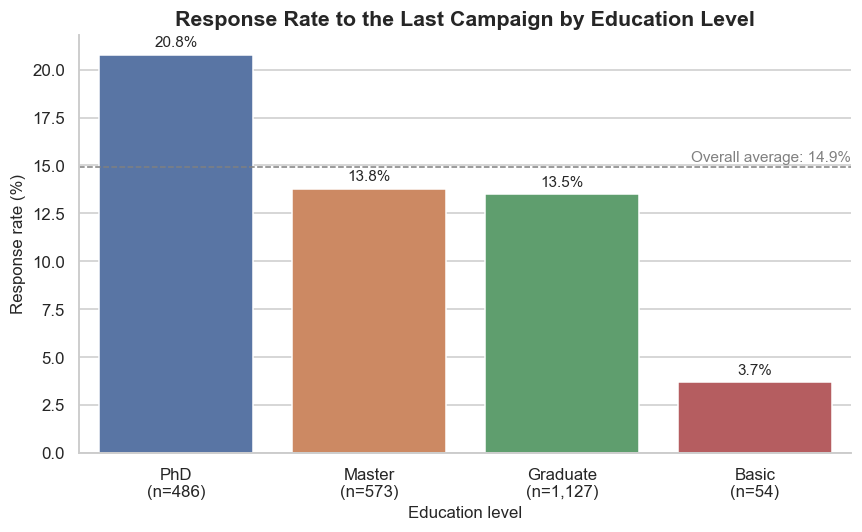

In [96]:
# Chart 1: bar chart comparing categories
fig, ax = plt.subplots(figsize=(8, 5))

sns.barplot(data=q1, x="Education", y="response_rate_pct",
            hue="Education", legend=False, ax=ax)

# Reference line: overall response rate
overall_rate = 100 * df["Response"].mean()
ax.axhline(overall_rate, color="grey", linestyle="--", linewidth=1)
ax.text(len(q1) - 0.5, overall_rate + 0.3, f"Overall average: {overall_rate:.1f}%",
        ha="right", color="grey", fontsize=10)

# Value labels on bars
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3, fontsize=10)

# Show sample size under each category (small groups are less reliable)
ax.set_xticks(range(len(q1)))
ax.set_xticklabels([f"{e}\n(n={n:,})" for e, n in zip(q1["Education"], q1["nb_customers"])])

ax.set_title("Response Rate to the Last Campaign by Education Level")
ax.set_xlabel("Education level")
ax.set_ylabel("Response rate (%)")
sns.despine()
plt.tight_layout()
plt.show()

## Graphique 2 : Dépense et réponse par quartile de revenu (bar + line)

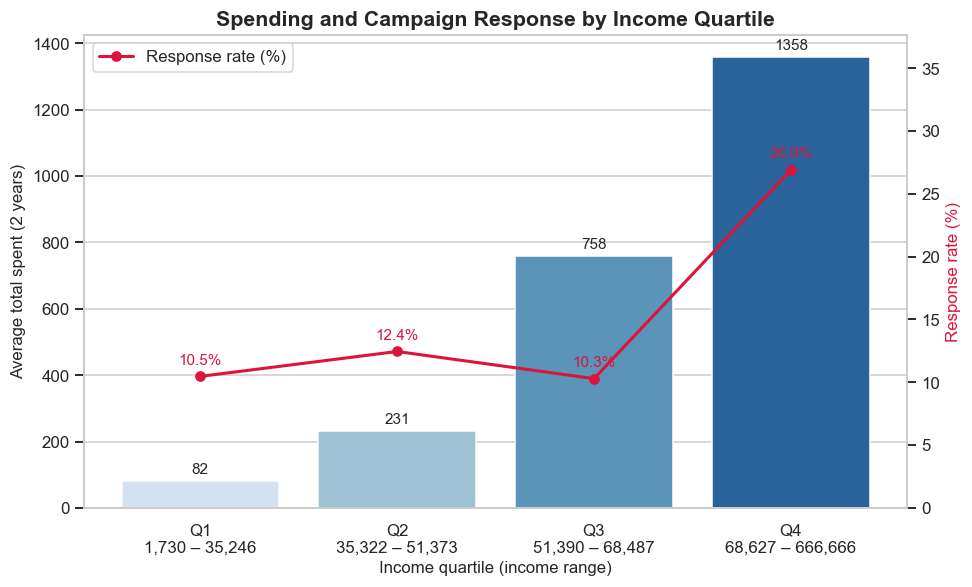

In [98]:
# Chart 2: bars (average spend) + line on secondary axis (response rate)
labels = [f"Q{int(r.income_quartile)}\n{r.min_income:,.0f} – {r.max_income:,.0f}"
          for r in q2.itertuples()]

fig, ax1 = plt.subplots(figsize=(9, 5.5))

sns.barplot(x=labels, y=q2["avg_total_spent"], hue=labels, legend=False,
            palette="Blues", ax=ax1)
for container in ax1.containers:
    ax1.bar_label(container, fmt="%.0f", padding=3, fontsize=10)

ax1.set_xlabel("Income quartile (income range)")
ax1.set_ylabel("Average total spent (2 years)")

# Secondary axis for the response rate
ax2 = ax1.twinx()
ax2.plot(range(len(q2)), q2["response_rate_pct"], color="crimson",
         marker="o", linewidth=2, label="Response rate (%)")
for i, v in enumerate(q2["response_rate_pct"]):
    ax2.annotate(f"{v:.1f}%", (i, v), textcoords="offset points",
                 xytext=(0, 8), ha="center", color="crimson", fontsize=10)
ax2.set_ylabel("Response rate (%)", color="crimson")
ax2.grid(False)  # avoid double grid
ax2.set_ylim(0, q2["response_rate_pct"].max() * 1.4)
ax2.legend(loc="upper left")

ax1.set_title("Spending and Campaign Response by Income Quartile")
plt.tight_layout()
plt.show()

## Graphique 3 : Répartition du chiffre d’affaires par catégorie (horizontal bar)

AttributeError: 'NoneType' object has no attribute 'get_bbox'

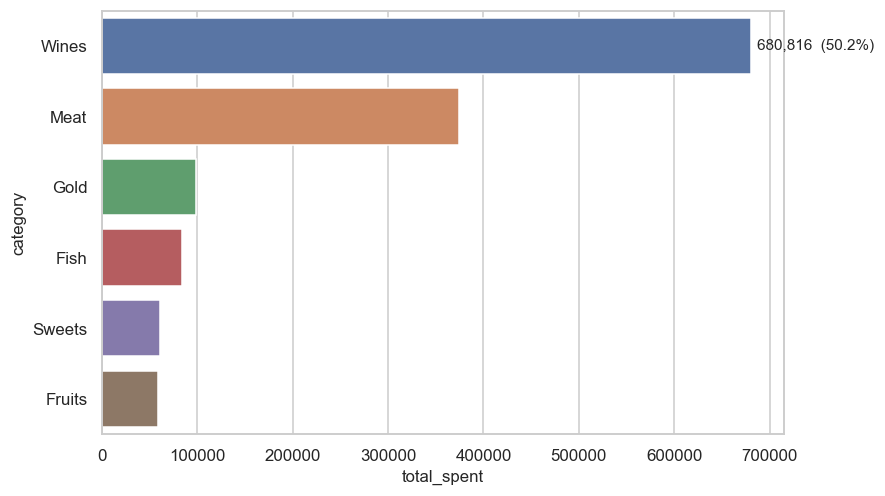

In [100]:
# Chart 3: composition with 6 categories -> horizontal bar (pie chart only if <= 5 categories)
fig, ax = plt.subplots(figsize=(8, 5))

sns.barplot(data=q3, y="category", x="total_spent",
            hue="category", legend=False, orient="h", ax=ax)

# Labels: absolute value + share of total
labels = [f"{v:,.0f}  ({s:.1f}%)" for v, s in zip(q3["total_spent"], q3["share_pct"])]
ax.bar_label(ax.containers[0], labels=labels, padding=4, fontsize=10)

ax.set_xlim(0, q3["total_spent"].max() * 1.25)  # room for labels
ax.set_title("Total Spending by Product Category")
ax.set_xlabel("Total spent (2 years)")
ax.set_ylabel("")
sns.despine()
plt.tight_layout()
plt.show()

## Graphique 4 : Canaux d’achat par profil familial (grouped bar)

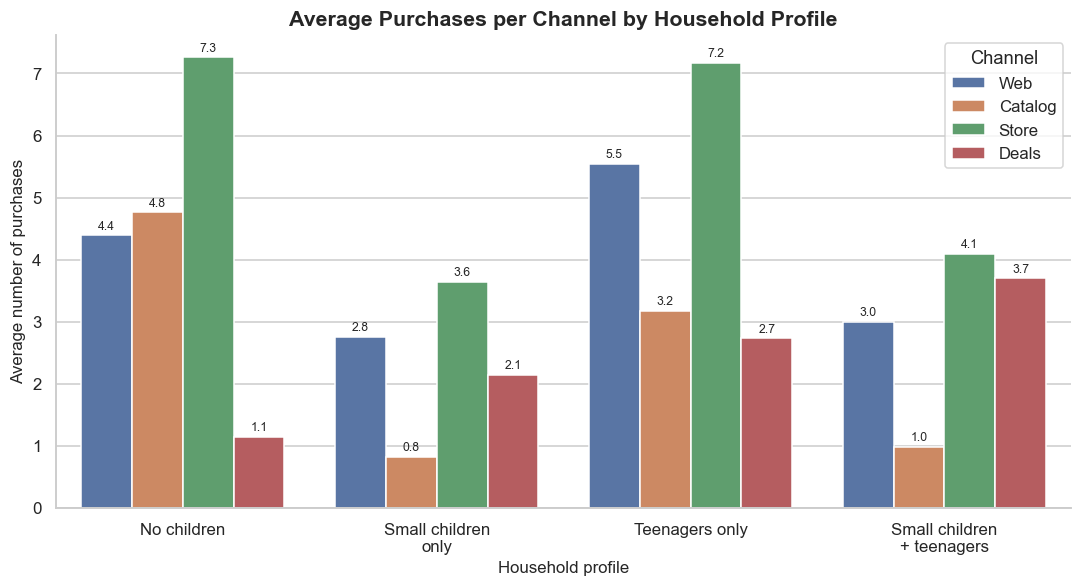

In [105]:
# Chart 4: grouped bar chart (channels x household profile)
# Rename columns so the code works with either version of the query
q4_plot = q4.rename(columns={
    "avg_web_purchases": "Web",
    "avg_catalog_purchases": "Catalog",
    "avg_store_purchases": "Store",
    "avg_deals_purchases": "Deals",
}).copy()

# Remove the "1. " ordering prefix and wrap long labels
q4_plot["household_profile"] = (q4_plot["household_profile"]
                                .str.replace(r"^\d\.\s*", "", regex=True)
                                .apply(lambda s: textwrap.fill(s, 14)))

q4_long = q4_plot.melt(id_vars=["household_profile", "nb_customers"],
                       value_vars=["Web", "Catalog", "Store", "Deals"],
                       var_name="Channel", value_name="avg_purchases")

fig, ax = plt.subplots(figsize=(10, 5.5))
sns.barplot(data=q4_long, x="household_profile", y="avg_purchases",
            hue="Channel", ax=ax)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f", padding=2, fontsize=8)

ax.set_title("Average Purchases per Channel by Household Profile")
ax.set_xlabel("Household profile")
ax.set_ylabel("Average number of purchases")
ax.legend(title="Channel", loc="upper right")
sns.despine()
plt.tight_layout()
plt.show()

## Graphique 5 : Performance des campagnes (bar chart)

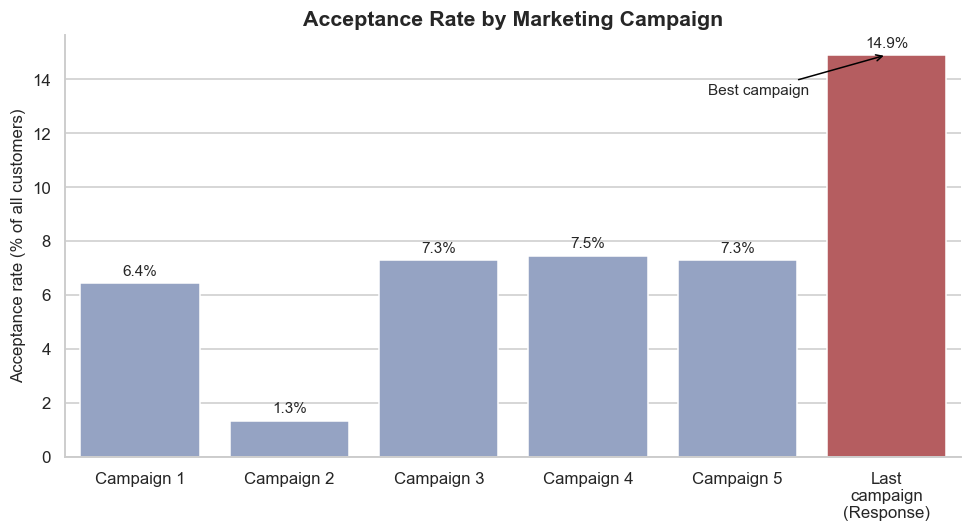

In [107]:
# Chart 5: bar chart comparing campaigns, best campaign highlighted
best_idx = q5["acceptance_rate_pct"].idxmax()
colors = ["#c44e52" if i == best_idx else "#8da0cb" for i in q5.index]

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=q5, x="campaign", y="acceptance_rate_pct",
            hue="campaign", palette=colors, legend=False, ax=ax)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3, fontsize=10)

# Annotation pointing to the best campaign
best = q5.loc[best_idx]
ax.annotate("Best campaign", xy=(best_idx, best["acceptance_rate_pct"]),
            xytext=(best_idx - 1.2, best["acceptance_rate_pct"] * 0.9),
            arrowprops=dict(arrowstyle="->", color="black"), fontsize=10)

ax.set_xticks(range(len(q5)))
ax.set_xticklabels([textwrap.fill(c, 12) for c in q5["campaign"]])
ax.set_title("Acceptance Rate by Marketing Campaign")
ax.set_xlabel("")
ax.set_ylabel("Acceptance rate (% of all customers)")
sns.despine()
plt.tight_layout()
plt.show()